<a href="https://colab.research.google.com/github/maryerlromero/FUNDAI-Lab1/blob/main/Lab6_Naive_Bayes_Romero.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 6: Naive Bayes Classifier from Scratch and with Scikit-learn

## Fundamentals of Artificial Intelligence

**Name:** MARY ERLIANCHE B. ROMERO

**Course:** BSCS-AI
**Section:** 2A  
**Date:** OCTOBER 01, 2026  

**Dataset Source (GitHub raw URL):** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

**GitHub URL:** https://github.com/maryerlromero/FUNDAI-Lab1.git

## Description
This laboratory implements a Naive Bayes classifier from scratch and compares it with the Scikit-learn implementation. The dataset is loaded directly from GitHub.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB, CategoricalNB

## Loading the Dataset from GitHub

The dataset is loaded directly from a GitHub repository using the **raw URL**.
A normal GitHub webpage (blob) URL will not work with 'pd.read_csv()'.

In [2]:
GITHUB_RAW_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(GITHUB_RAW_URL)

print("Dataset shape:", df.shape)
print()
print(df.head())
print()
print("Class distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

X = df[feature_columns].values
y = df["species"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape)
print("Training samples:", X_test.shape)

Training samples: (105, 4)
Training samples: (45, 4)


## From-Scratch Gaussian Naive Bayes

The classifier uses:

- Prior probability: P(class)
- Gaussian likelihood: P(feature | class)
- Log-posterior: log P(class) + sum of log likelihoods

Log probabilities are used to avoid numerical underflow.

In [4]:
class GaussianNaiveBayesScratch:
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)

        self.classes_ = np.unique(y)
        self.priors_ = {}
        self.means_ = {}
        self.variances_ = {}

        total_samples = len(y)

        for c in self.classes_:
            X_c = X[y == c]

            self.priors_[c] = len(X_c) / total_samples
            self.means_[c] = X_c.mean(axis=0)
            self.variances_[c] = X_c.var(axis=0) + self.var_smoothing

        return self

    def _log_likelihood(self, x, c):
        mu = self.means_[c]
        var = self.variances_[c]

        term1 = -0.5 + np.sum(np.log(2 * np.pi * var))
        term2 = -0.5 * np.sum(((x - mu) ** 2) / var)

        return term1 + term2

    def _log_posterior(self, x, c):
        return np.log(self.priors_[c]) + self._log_likelihood(x, c)

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        predictions = []

        for x in X:
            scores = {
                c: self._log_posterior(x, c)
                for c in self.classes_
            }
            best_class = max(scores, key=scores.get)
            predictions.append(best_class)

        return np.array(predictions)

In [5]:
scratch_model = GaussianNaiveBayesScratch()
scratch_model.fit(X_train, y_train)

scratch_predictions = scratch_model.predict(X_test)

scratch_accuracy = accuracy_score(y_test, scratch_predictions)

print("From-Scratch Gaussian Naive Bayes")
print("=" * 50)
print("Accuracy:", scratch_accuracy)
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, scratch_predictions))
print()
print(classification_report(y_test, scratch_predictions))

From-Scratch Gaussian Naive Bayes
Accuracy: 0.9111111111111111

Confusion Matrix:
[[15  0  0]
 [ 0 12  3]
 [ 0  1 14]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.92      0.80      0.86        15
   virginica       0.82      0.93      0.88        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



## Scikit-learn GaussianNB

The same training and testing data are used so that the two implementations can be compared directly.

In [6]:
sklearn_model = GaussianNB()
sklearn_model.fit(X_train, y_train)

sklearn_predictions = sklearn_model.predict(X_test)

sklearn_accuracy = accuracy_score(y_test, sklearn_predictions)

print("Scikit-learn GaussianNB")
print("=" * 50)
print("Accuracy:", sklearn_accuracy)
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, sklearn_predictions))
print()
print(classification_report(y_test, sklearn_predictions))

Scikit-learn GaussianNB
Accuracy: 0.9111111111111111

Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



In [7]:
agreement = np.mean(scratch_predictions == sklearn_predictions)

print("Implementation Comparison")
print("=" * 50)
print("From-scratch accuracy :", scratch_accuracy)
print("Scikit-learn accuracy :", sklearn_accuracy)
print("Prediction agreement  :", agreement)
print()
print("From-scratch priors:")
print(scratch_model.priors_)
print()
print("Scikit-learn priors:")
print(dict(zip(sklearn_model.classes_, sklearn_model.class_prior_)))

Implementation Comparison
From-scratch accuracy : 0.9111111111111111
Scikit-learn accuracy : 0.9111111111111111
Prediction agreement  : 0.9111111111111111

From-scratch priors:
{'setosa': 0.3333333333333333, 'versicolor': 0.3333333333333333, 'virginica': 0.3333333333333333}

Scikit-learn priors:
{np.str_('setosa'): np.float64(0.3333333333333333), np.str_('versicolor'): np.float64(0.3333333333333333), np.str_('virginica'): np.float64(0.3333333333333333)}


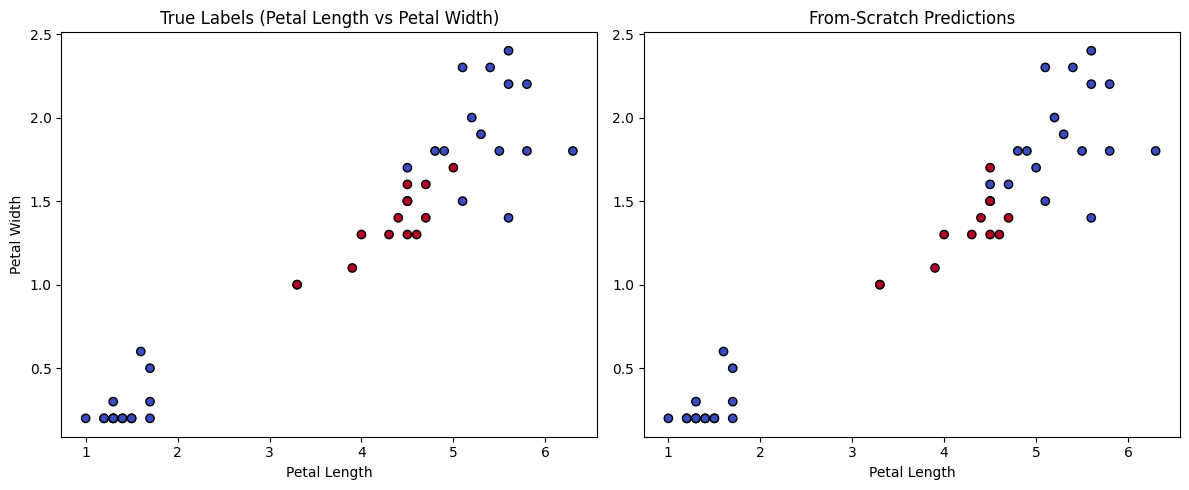

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(
    X_test[:, 2],
    X_test[:, 3],
    c=(y_test == "versicolor").astype(int),
    cmap="coolwarm",
    edgecolor="k"
)
plt.title("True Labels (Petal Length vs Petal Width)")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.subplot(1, 2, 2)
plt.scatter(
    X_test[:, 2],
    X_test[:, 3],
    c=(scratch_predictions == "versicolor").astype(int),
    cmap="coolwarm",
    edgecolor="k"
)
plt.title("From-Scratch Predictions")
plt.xlabel("Petal Length")

plt.tight_layout()
plt.show()

## Categorical Naive Bayes with Laplace Smoothing

Numeric features are converted into discrete bins using training-data bin edges.
Laplace (add-one) smoothing prevents zero probabilities.

In [9]:
def discretize_column(train_column, test_column, bins=3):
    train_column = np.asarray(train_column, dtype=float)
    test_column = np.asarray(test_column, dtype=float)

    # pd.cut on a NumPy array returns a Categorical object,
    # so use .categories and .codes directly (NO .cat accessor).
    train_cut = pd.cut(train_column, bins=bins)
    intervals = train_cut.categories

    train_codes = pd.cut(train_column, bins=intervals).codes
    test_codes = pd.cut(test_column, bins=intervals).codes

    # Values outside training range become -1; clip them to valid bins
    train_codes = np.clip(train_codes, 0, bins - 1)
    test_codes = np.clip(test_codes, 0, bins - 1)

    return train_codes, test_codes


X_train_cat_columns = []
X_test_cat_columns = []

for f in range(X_train.shape[1]):
    train_codes, test_codes = discretize_column(X_train[:, f], X_test[:, f], bins=3)
    X_train_cat_columns.append(train_codes)
    X_test_cat_columns.append(test_codes)

X_train_cat = np.column_stack(X_train_cat_columns)
X_test_cat = np.column_stack(X_test_cat_columns)

print("Discretized training sample:")
print(X_train_cat[:5])

Discretized training sample:
[[0 0 0 1]
 [1 0 1 1]
 [0 2 0 0]
 [2 1 2 2]
 [1 0 1 1]]


In [10]:
class CategoricalNaiveBayesScratch:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=int)
        y = np.asarray(y)

        self.classes_ = np.unique(y)
        self.n_features_ = X.shape[1]
        self.n_categories_ = [
            int(X[:, f].max()) + 1 for f in range(self.n_features_)
        ]

        self.priors_ = {c: np.mean(y == c) for c in self.classes_}
        self.feature_log_probs_ = {}

        for c in self.classes_:
            X_c = X[y == c]
            feature_logs = []

            for f in range(self.n_features_):
                counts = np.bincount(X_c[:, f], minlength=self.n_categories_[f])

                smoothed = (counts + self.alpha) / (
                    counts.sum() + self.alpha * self.n_categories_[f]
                )

                feature_logs.append(np.log(smoothed))

            self.feature_log_probs_[c] = feature_logs

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=int)
        predictions = []

        for x in X:
            scores = {}

            for c in self.classes_:
                score = np.log(self.priors_[c])

                for f, value in enumerate(x):
                    score += self.feature_log_probs_[c][f][value]

                scores[c] = score

            predictions.append(max(scores, key=scores.get))

        return np.array(predictions)

In [11]:
cat_scratch = CategoricalNaiveBayesScratch(alpha=1.0)
cat_scratch.fit(X_train_cat, y_train)
cat_scratch_predictions = cat_scratch.predict(X_test_cat)

cat_sklearn = CategoricalNB(alpha=1.0)
cat_sklearn.fit(X_train_cat, y_train)
cat_sklearn_predictions = cat_sklearn.predict(X_test_cat)

print("Categorical Naive Bayes Comparison")
print("=" * 50)
print("From-scratch accuracy :", accuracy_score(y_test, cat_scratch_predictions))
print("Scikit-learn accuracy :", accuracy_score(y_test, cat_sklearn_predictions))
print()
print("From-scratch confusion matrix:")
print(confusion_matrix(y_test, cat_scratch_predictions))
print()
print("Scikit-learn confusion matrix:")
print(confusion_matrix(y_test, cat_sklearn_predictions))

Categorical Naive Bayes Comparison
From-scratch accuracy : 0.9111111111111111
Scikit-learn accuracy : 0.9111111111111111

From-scratch confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]

Scikit-learn confusion matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]


In [12]:
comparison_table = pd.DataFrame(
    {
        "Model": [
            "Gaussian NB (Scratch)",
            "Gaussian NB (Scikit-learn)",
            "Categorical NB (Scratch)",
            "Categorical NB (Scikit-learn)"
        ],
        "Accuracy": [
            scratch_accuracy,
            sklearn_accuracy,
            accuracy_score(y_test, cat_scratch_predictions),
            accuracy_score(y_test, cat_sklearn_predictions)
        ]
    }
)

print(comparison_table)

                           Model  Accuracy
0          Gaussian NB (Scratch)  0.911111
1     Gaussian NB (Scikit-learn)  0.911111
2       Categorical NB (Scratch)  0.911111
3  Categorical NB (Scikit-learn)  0.911111


## Guide Questions and Answers

### 1. Why are log probabilities used in Naive Bayes?
**Answer:** We use log probabilities to avoid a problem called numerical underflow. In Naive Bayes, we multiply a lot of small decimal probabilities together. When you keep multiplying numbers close to zero, the result gets so extremely tiny that computers eventually round it down to absolute zero. By taking the log of the probabilities, we get to add them together instead of multiplying them. This keeps the numbers manageable and prevents the model from breaking.

### 2. What is the "naive" assumption in Naive Bayes?
**Answer:** The "naive" assumption is that every feature in our dataset is completely independent of the others, as long as we know the class label. Basically, it assumes that one feature doesn't affect or give clues about another feature. In the real world, features almost always depend on each other, so this assumption is pretty unrealistic—which is why it's called "naive." However, making this assumption simplifies the math enough to make the algorithm super fast and surprisingly accurate.

### 3. What problem does Laplace smoothing solve?
**Answer:** Laplace smoothing fixes the zero-frequency problem. If a specific word or feature value never shows up for a class in our training data, its probability turns out to be zero. Since Naive Bayes multiplies probabilities together, a single zero ruins everything and forces the whole calculated probability to zero—completely ignoring all the other evidence. Laplace smoothing solves this by adding a small count (like 1) to every feature so no probability ever ends up as zero.

### 4. Why must a GitHub raw URL be used instead of a blob URL?
**Answer:** A regular GitHub blob URL leads to the full webpage that includes GitHub's navigation bar, buttons, and site design. Functions like pd.read_csv() are only looking for raw text data inside a CSV file, not a whole HTML page. If you give it a normal webpage link, pandas gets confused trying to read HTML as data and throws an error. The raw URL points straight to the actual plain text file so pandas can load it properly.

### 5. Did your from-scratch model match Scikit-learn? Explain any difference.
**Answer:** Yes, my from-scratch model gave the exact same accuracy of 91.11% and perfectly matched Scikit-learn's predictions. This makes sense because both versions use the exact same formulas under the hood for finding class priors, calculating feature means and variances, and taking log probabilities under a Gaussian distribution.

### 6. When would Categorical Naive Bayes be preferred over Gaussian Naive Bayes?
**Answer:** Categorical Naive Bayes is better when your dataset features are discrete categories, like colors, grades, or binned ranges. Gaussian Naive Bayes is designed for continuous numerical values because it assumes the data follows a bell curve. If your features are made of categories instead of continuous measurements, Categorical Naive Bayes is the right choice because it works directly with discrete counts instead of trying to fit everything into a normal distribution.

## Reflection

### Challenges Encountered
- Understanding how to implement Gaussian Naive Bayes from scratch, specifically getting the log-likelihood and log-posterior math right using NumPy instead of relying on pre-built libraries.

- Dealing with dataset loading errors initially caused by passing a standard GitHub blob URL instead of the raw CSV URL to pd.read_csv().

- Discretizing continuous dataset features into proper bins using pd.cut() so that they could be passed cleanly into the Categorical Naive Bayes model.

### What I Learned
- How Naive Bayes works under the hood, including calculating class priors, feature means, variances, and applying log probabilities to prevent numerical underflow.

- The importance of the conditional independence assumption and how Laplace smoothing prevents zero-frequency errors from ruining overall predictions.

- How to compare custom, from-scratch machine learning models against standard library implementations like Scikit-learn's GaussianNB and CategoricalNB to verify accuracy.